# From gene identity to contextual functional organization

How does a frozen transcriptome model transform sample-invariant gene identity vectors into context-dependent gene representations, and does their functional geometry add signal beyond expression and coexpression?

We compare the static lookup table (L0) with contextual states at L1, L6, and L12. Quantitative neighborhood and prediction tests are distinguished from exploratory projections. Results concern known GO/KEGG annotations; they do not establish causal biological mechanisms.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Image

candidates = [Path.cwd(), Path.cwd() / 'benchmarks' / 'representation_analysis',
              Path.cwd() / 'representation_analysis']
REPORT = next((p.resolve() for p in candidates if (p / 'data' / 'provenance.json').is_file()), None)
if REPORT is None:
    raise FileNotFoundError('Run from the repository root, benchmarks/, or benchmarks/representation_analysis/')
DATA, FIGURES = REPORT / 'data', REPORT / 'figures'
FIGURES.mkdir(exist_ok=True)
FIGURE_DATA = DATA / 'figure_data'
FIGURE_DATA.mkdir(exist_ok=True)
provenance = json.loads((DATA / 'provenance.json').read_text())
validation = json.loads((DATA / 'validation.json').read_text())
assert validation['status'] == 'passed'
for record in provenance['cached_files']:
    path = DATA / record['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], record['file']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.dpi': 250, 'pdf.fonttype': 42})
COHORT_COLORS = {'GTEx': '#237A8A', 'TCGA': '#BD5544'}
LAYERS = ['L0_static', 'L1_early', 'L6_middle', 'L12_final']
LABELS = ['L0', 'L1', 'L6', 'L12']
def save_figure(fig, stem, values):
    fig.savefig(FIGURES / f'{stem}.png', dpi=250, bbox_inches='tight')
    fig.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    values.to_csv(FIGURE_DATA / f'{stem}.csv', index=False)
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(fig)


## Data and methods

We used the frozen Bridge model to study how gene representations change across normal tissues and cancers. The quantitative benchmark uses 200 GTEx samples from 10 tissues and 200 TCGA samples from 10 tumor contexts, with consistent preprocessing. The context-colored visualization uses a separate cohort of 10 corresponding normal-tissue/cancer groups, also with 20 samples per group.

We compared static gene embeddings—the same lookup table in every sample—with representations from later model layers. Using GO and KEGG annotations, we asked whether functionally related genes became neighbors, formed coherent networks, and could be identified in held-out pair-prediction tests.

We evaluated the frozen model on GTEx and TCGA, two data sources separate from the ARCHS4 pretraining collection. Normal tissues and tumors were unpaired.

In [2]:
manifest = pd.read_csv(DATA / 'sample_manifest.csv')
assert len(manifest) == 400 and not manifest.duplicated(['dataset', 'sample_id']).any()
assert manifest.groupby(['dataset', 'context']).size().eq(20).all()
display(manifest.groupby(['dataset', 'context']).size().rename('Samples').reset_index())


,dataset,context,Samples
0,GTEx,cerebellum,20
1,GTEx,cortex,20
2,GTEx,heart,20
3,GTEx,liver,20
4,GTEx,lung,20
5,GTEx,pancreas,20
6,GTEx,skeletal muscle,20
7,GTEx,spleen,20
8,GTEx,subcutaneous adipose,20
9,GTEx,testis,20


## 1. Static gene embeddings: a baseline for functional organization

Each gene has a fixed embedding that is identical across samples. We used PCA to measure how its variation is distributed across dimensions, and clustering and neighborhood-enrichment tests to ask whether genes group by biological function.

We compared raw embeddings, L2-normalized embeddings, and embeddings with post-hoc LayerNorm. The main clustering analysis used K-means with 10 clusters, seeds 42/43/44, and three initializations. We also used 10 annotation-based null comparisons and one vector-shuffle null.

The embeddings required nearly all dimensions to describe their variation. Silhouette scores near zero and very low adjusted Rand index (ARI) values indicated poorly separated clusters with little agreement across runs.

The t-SNE visualization used saved coordinates calculated after reducing the embeddings to 50 principal components. Genes are colored by mean training-set TPM. The plot is descriptive and does not independently establish functional organization.

,representation,pca_participation_ratio,pcs_for_90pct,silhouette,cluster_stability_ari,significant_go_terms,significant_kegg_terms
0,raw,495.091388,443,-0.000276,0.006185,0,0
1,l2_cosine,495.143555,443,0.000048,0.004547,0,4
2,layernorm,494.210990,442,-0.000048,0.005769,2,0


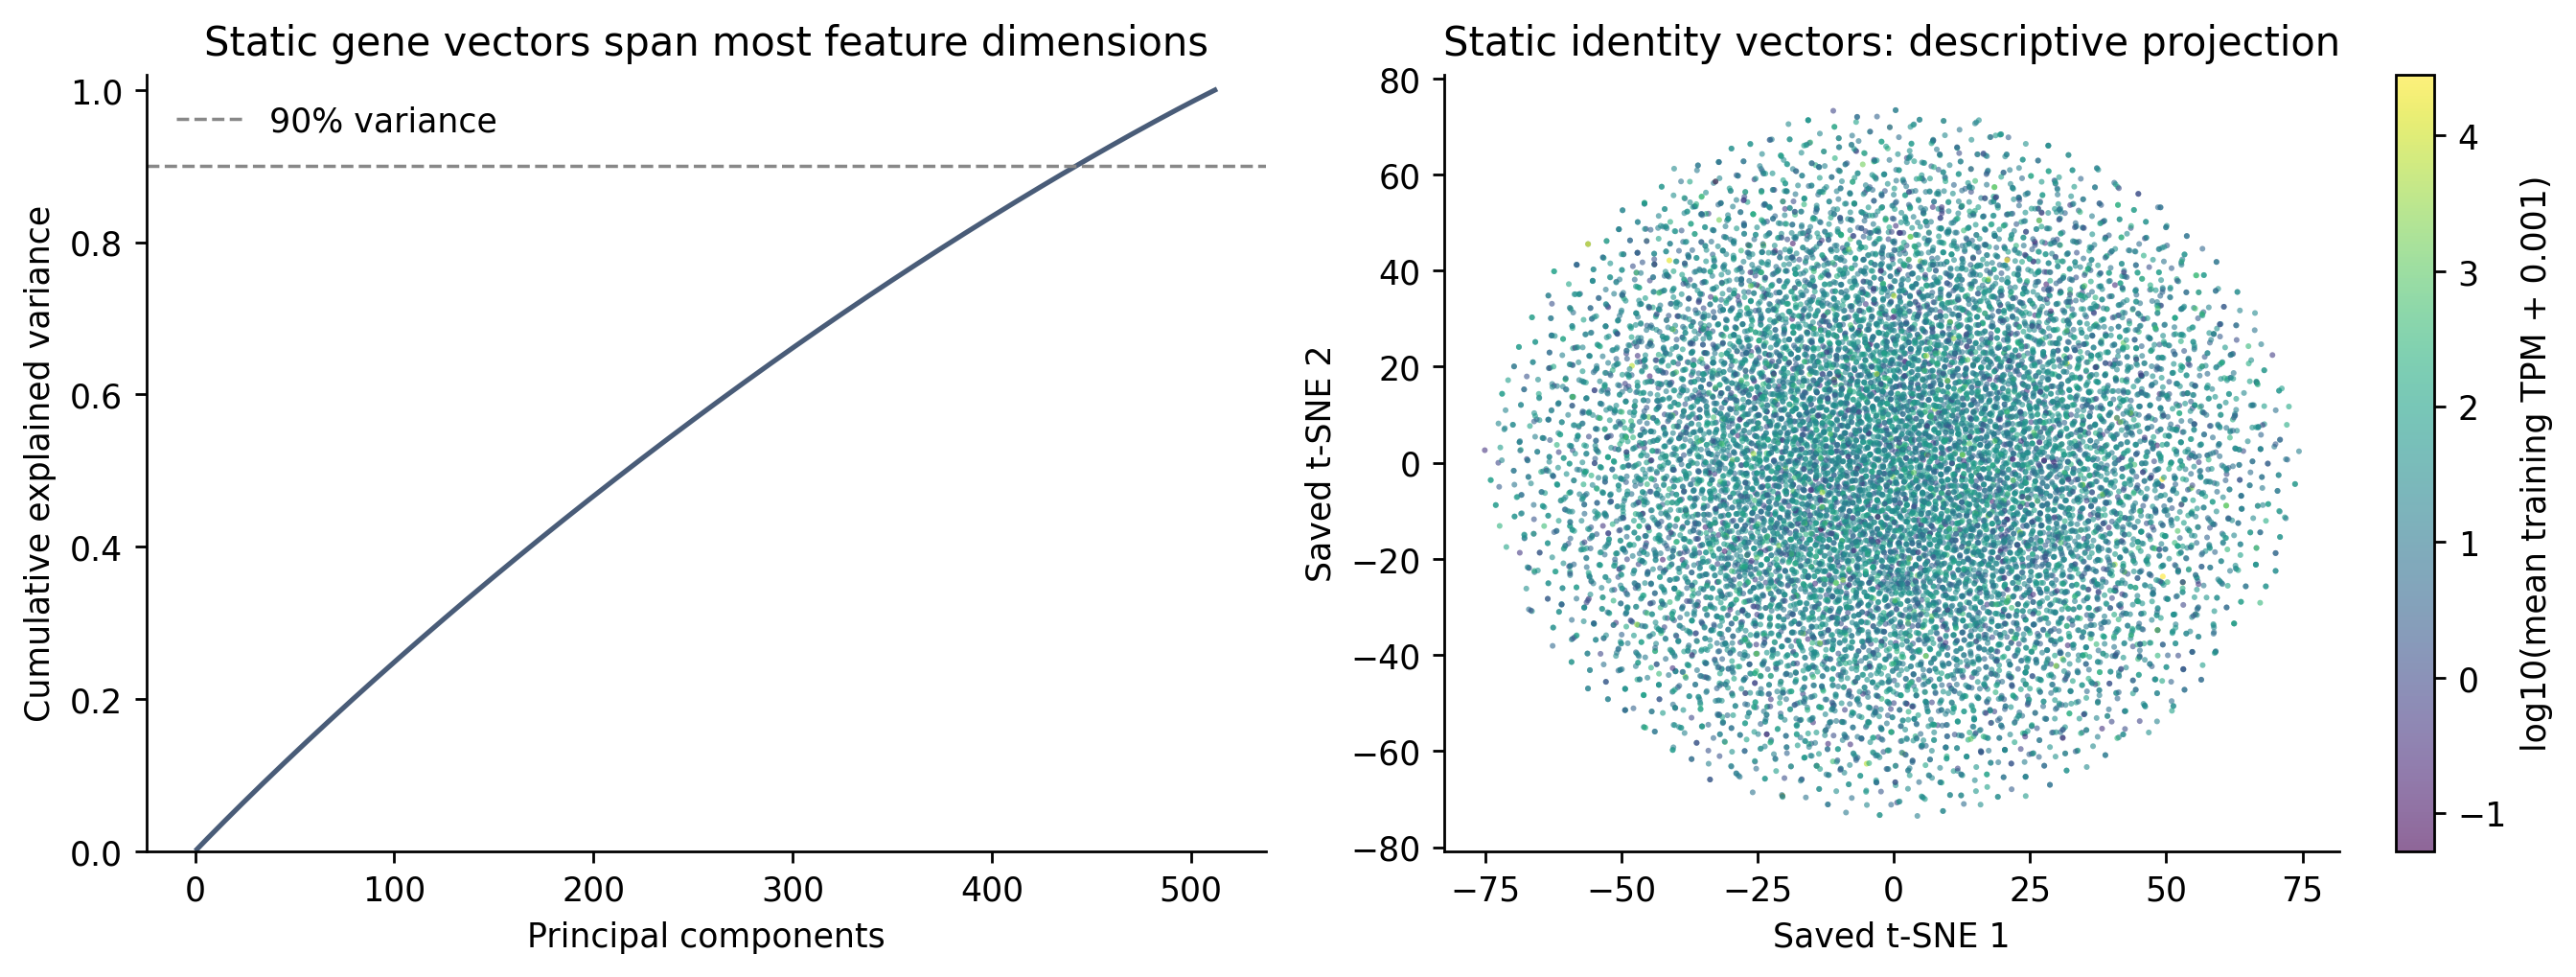

In [3]:
static = pd.read_csv(DATA / 'static_geometry.csv')
pca = pd.read_csv(DATA / 'static_pca_variance.csv')
coords = pd.read_csv(DATA / 'static_gene_coordinates.csv')
assert len(coords) == 15165 and coords.gene.is_unique
assert list(coords.token_id) == list(range(1, 15166))
display(static[['representation','pca_participation_ratio','pcs_for_90pct','silhouette',
                'cluster_stability_ari','significant_go_terms','significant_kegg_terms']].round(6))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(pca.pc, pca.cumulative_explained_variance, color='#495C78')
axes[0].axhline(.9, color='#888', ls='--', lw=1, label='90% variance')
axes[0].set(xlabel='Principal components', ylabel='Cumulative explained variance',
            title='Static gene vectors span most feature dimensions', ylim=(0,1.02))
axes[0].legend(frameon=False)
scatter = axes[1].scatter(coords.tsne_1, coords.tsne_2, c=coords.log10_average_training_tpm,
                          s=3, alpha=.6, cmap='viridis', linewidths=0, rasterized=True)
fig.colorbar(scatter, ax=axes[1], label='log10(mean training TPM + 0.001)')
axes[1].set(xlabel='Saved t-SNE 1', ylabel='Saved t-SNE 2', title='Static identity vectors: descriptive projection')
fig.tight_layout()
save_figure(fig, 'static_identity_geometry', coords)
pca.to_csv(FIGURE_DATA / 'static_pca_variance.csv', index=False)


## 2. Functional neighborhoods across sampled depths

Genes with shared GO or KEGG annotations increasingly become neighbors across L0, L1, L6, and L12. We measured enrichment among each gene’s 25 nearest neighbors using mean-centered cosine similarity, relative to 10 random-neighbor comparisons.

Error bars show SD across 200 samples. L0 is a shared static baseline and has no replicate error bar.

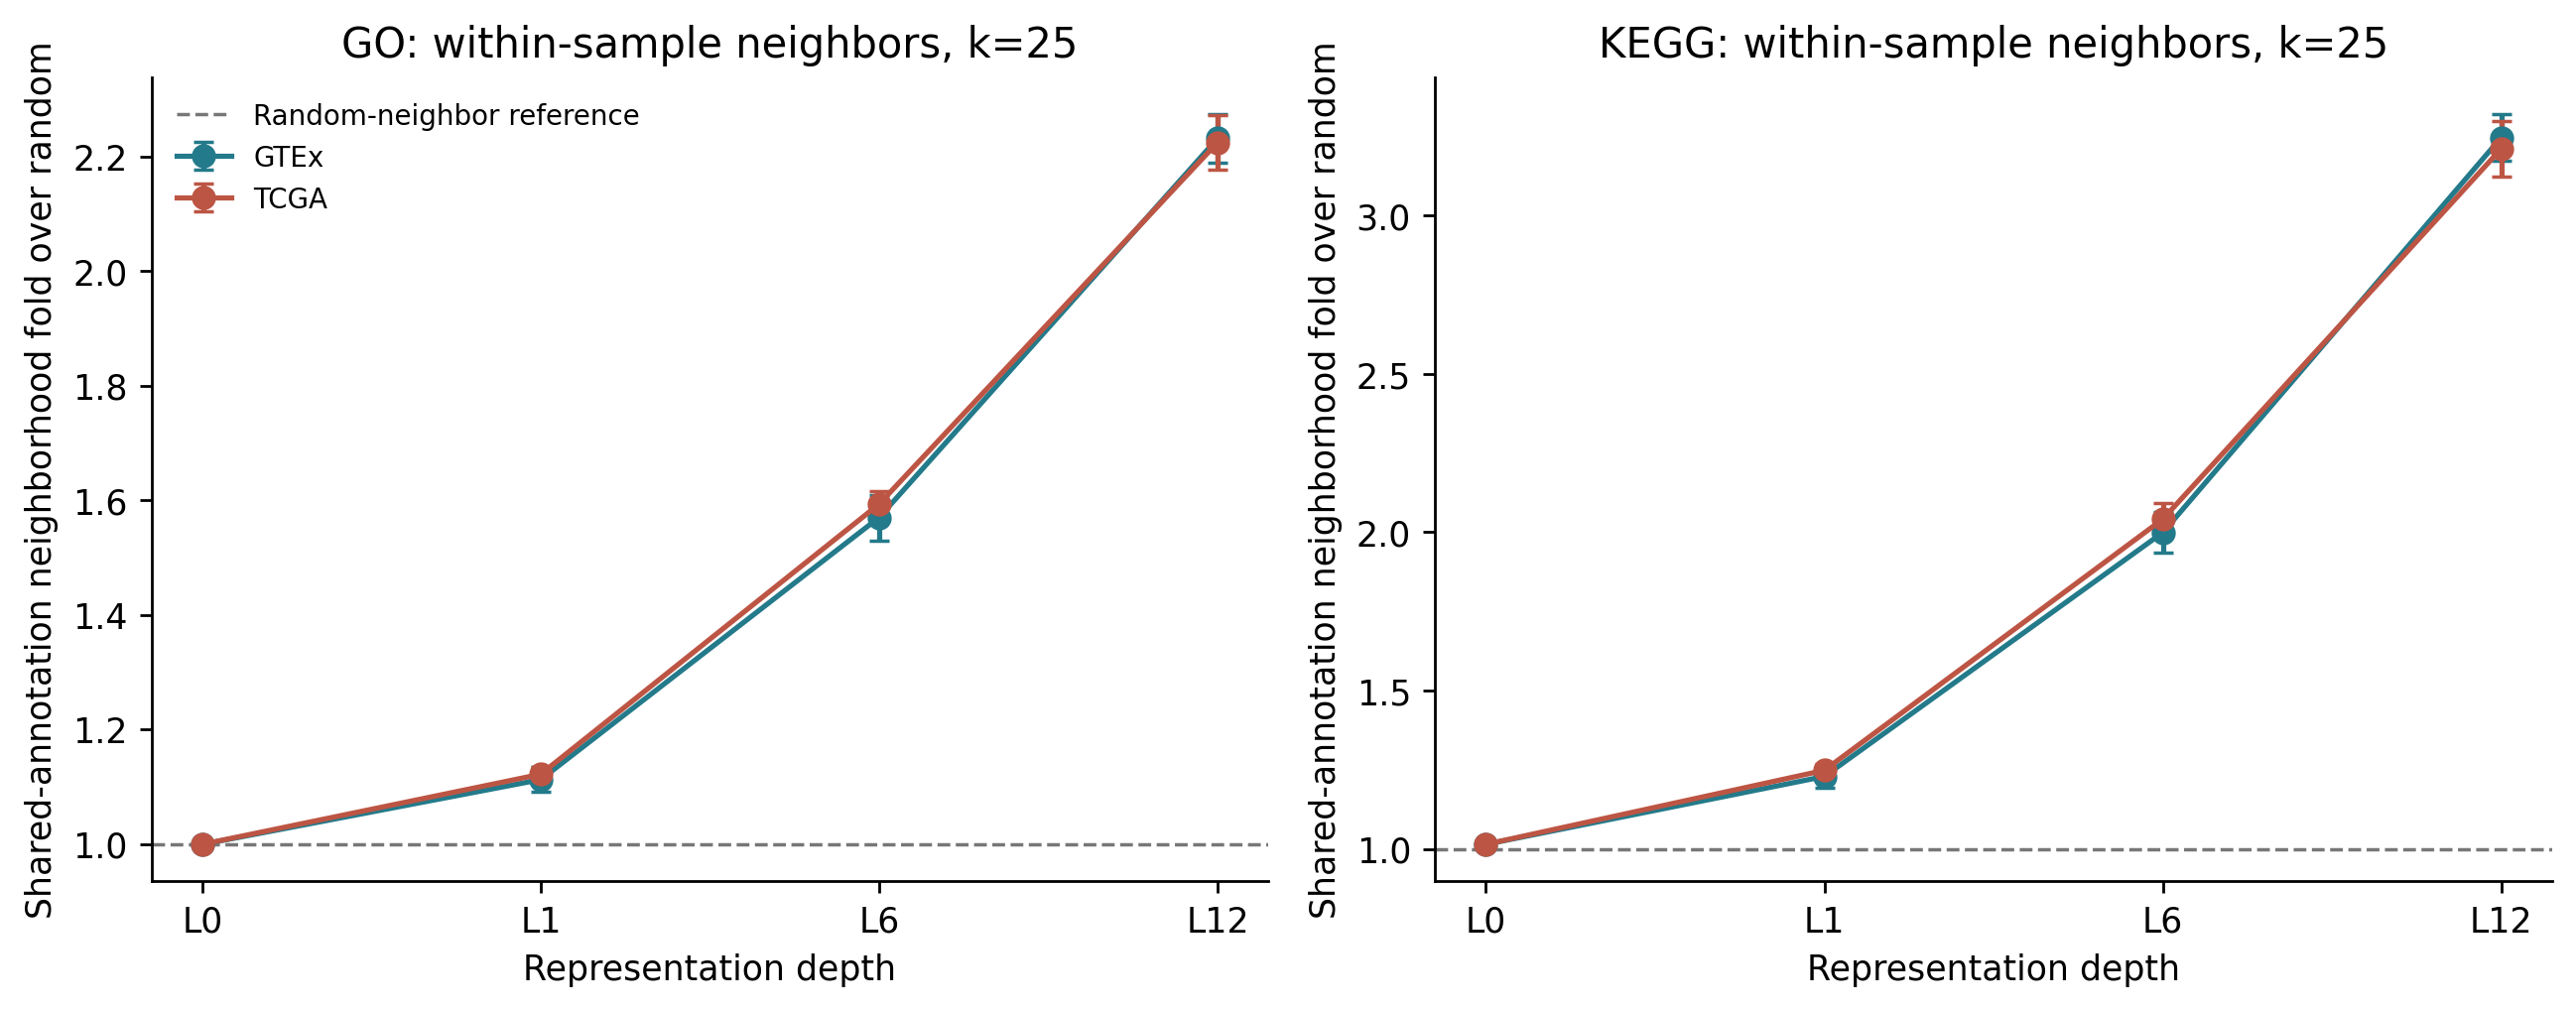

,dataset,library,layer,neighbor_fold,neighbor_fold_sd,samples_x
1,GTEx,GO,L0_static,0.999189,NaN,1
4,GTEx,KEGG,L0_static,1.014300,NaN,1
13,GTEx,GO,L12_final,2.231805,0.042576,200
16,GTEx,KEGG,L12_final,3.246897,0.074153,200
25,GTEx,GO,L1_early,1.112140,0.021664,200
28,GTEx,KEGG,L1_early,1.228650,0.035797,200
37,GTEx,GO,L6_middle,1.569937,0.039825,200
40,GTEx,KEGG,L6_middle,1.999080,0.063488,200
49,TCGA,GO,L0_static,0.999189,NaN,1
52,TCGA,KEGG,L0_static,1.014300,NaN,1


In [4]:
depth = pd.read_csv(DATA / 'depth_summary.csv')
samples = pd.read_csv(DATA / 'depth_per_sample.csv')
for row in depth.itertuples():
    q = samples[(samples.dataset == row.dataset) & (samples.layer == row.layer) &
                (samples.geometry == row.geometry) & (samples.library == row.library) & (samples.k == row.k)]
    assert len(q) == row.samples_x
    assert np.isclose(q.neighbor_fold.mean(), row.neighbor_fold, atol=1e-12, rtol=0)
    if len(q) > 1:
        assert np.isclose(q.neighbor_fold.std(ddof=1), row.neighbor_fold_sd, atol=1e-12, rtol=0)
primary_depth = depth.query("k == 25 and geometry == 'mean_centered_cosine'").copy()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharex=True)
for ax, library in zip(axes, ['GO','KEGG']):
    for dataset in ['GTEx','TCGA']:
        q = primary_depth[(primary_depth.dataset == dataset) & (primary_depth.library == library)].set_index('layer').loc[LAYERS]
        ax.errorbar(np.arange(4), q.neighbor_fold, yerr=q.neighbor_fold_sd.fillna(0), marker='o',
                    capsize=3, color=COHORT_COLORS[dataset], label=dataset)
    ax.axhline(1, color='#777', ls='--', lw=1, label='Random-neighbor reference')
    ax.set(xticks=range(4), xticklabels=LABELS, xlabel='Representation depth',
           ylabel='Shared-annotation neighborhood fold over random', title=f'{library}: within-sample neighbors, k=25')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, 'functional_depth', primary_depth)
display(primary_depth[['dataset','library','layer','neighbor_fold','neighbor_fold_sd','samples_x']].round(6))


### Gene representations across corresponding tissues and cancers

We visualized 500 genes across **10 corresponding normal-tissue and cancer groups**, averaging **20 samples per group** (200 GTEx and 200 TCGA samples). The pairs are mammary gland/BRCA, sigmoid colon/COAD, cortex/GBM, liver/LIHC, lung/LUAD, stomach/STAD, pancreas/PAAD, ovary/OV, adrenal gland/ACC, and testis/TGCT. Shared colors identify corresponding organs; cortex is an approximate brain reference for GBM. These are unpaired cohorts, not matched patients or cell types.

Each point represents one gene's average within a group. We subtract that gene's average across contexts within each dataset and layer to highlight context-dependent differences. All L0 points overlap because static embeddings do not vary across contexts. Each layer has its own joint GTEx/TCGA PCA-50/UMAP layout, so distances should not be compared directly across layers.

**This visualization uses a separate organ-corresponding cohort.** The functional enrichment, within/across-context cosine summaries, and expression-control results elsewhere in the notebook retain the original benchmark cohort. The visualization's exact samples and color mapping are saved in `data/context_visualization_sample_manifest.csv` and `data/context_visualization_palette.json`.

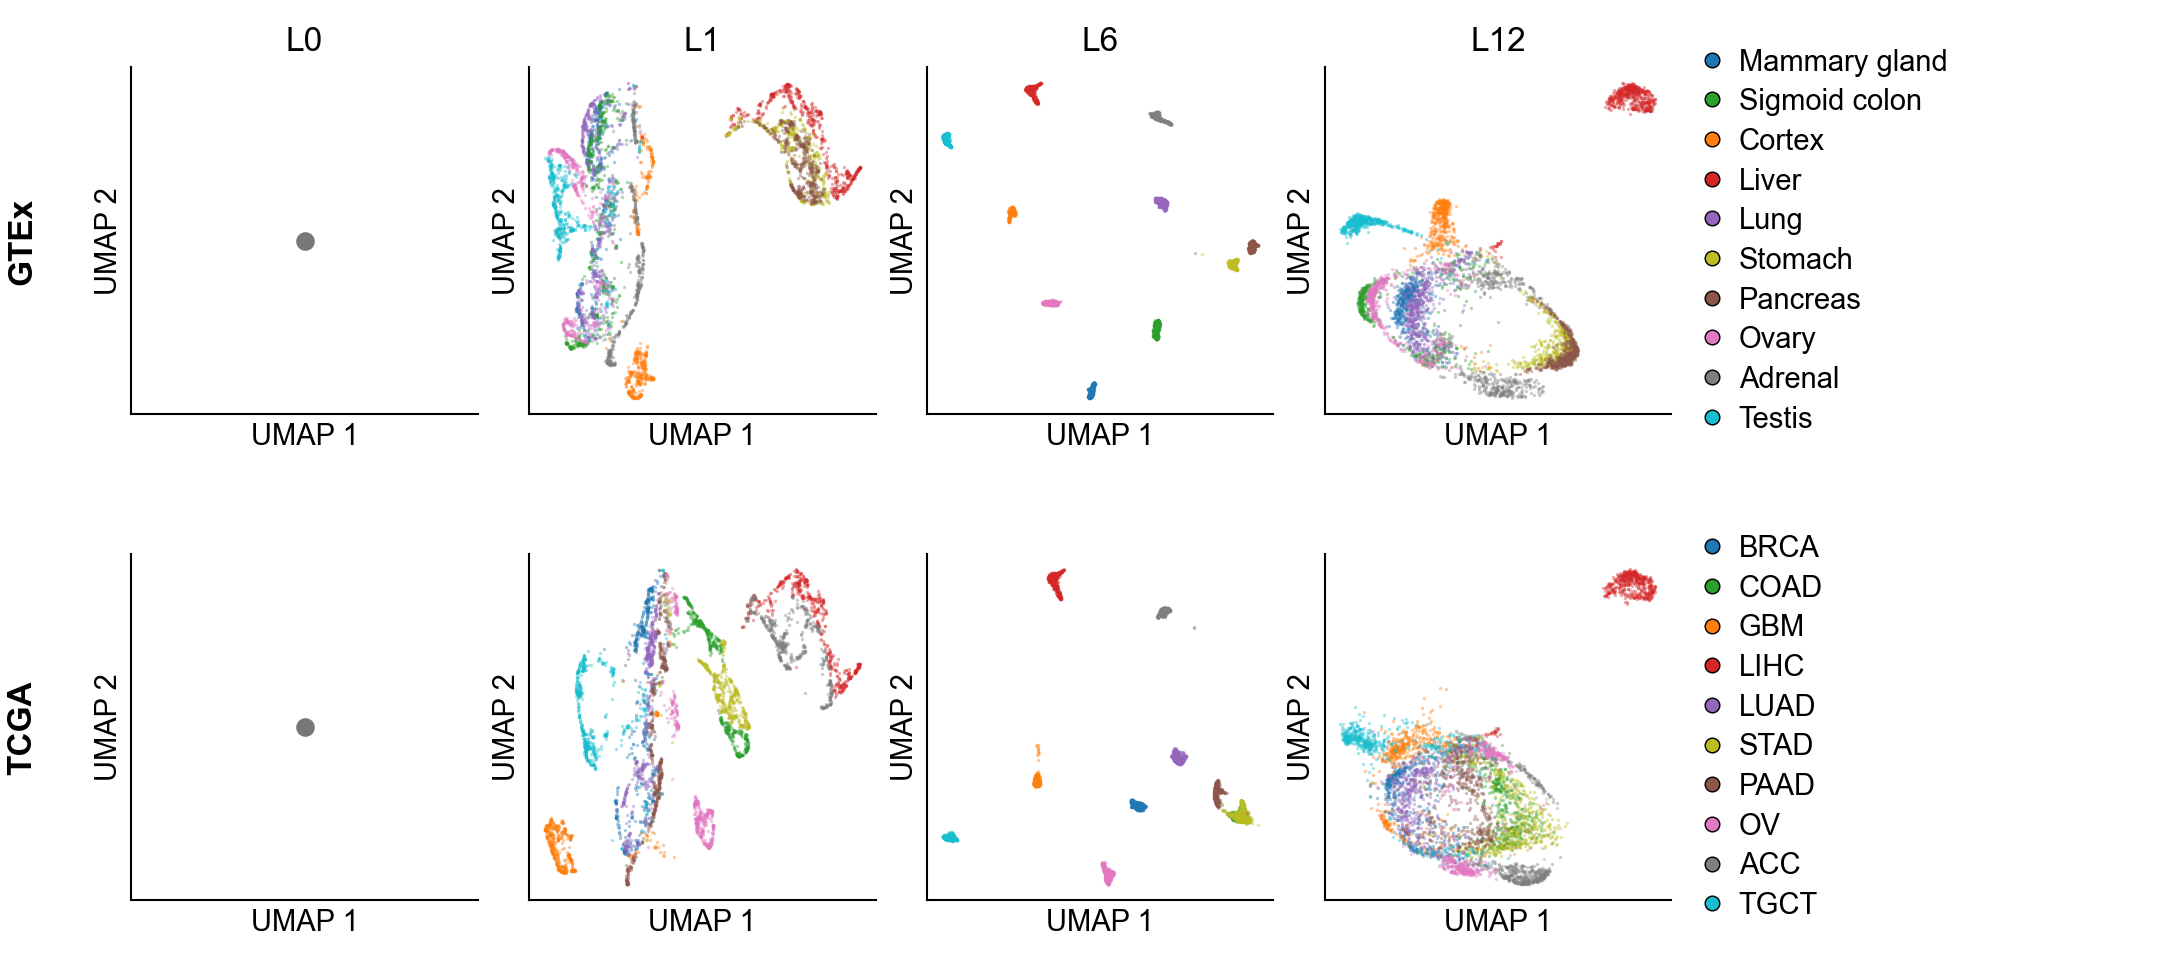

In [5]:
projection = pd.read_csv(DATA / 'context_umap_coordinates.csv')
assert len(projection) == 40000
# Register user-installed Arial even if this kernel's font cache predates installation.
from matplotlib import font_manager
for font_path in font_manager.findSystemFonts():
    if Path(font_path).name.lower().startswith('arial'):
        font_manager.fontManager.addfont(font_path)
font_manager.findfont(font_manager.FontProperties(family='Arial'), fallback_to_default=False)
# Final-size typography uses Nature's recommended Arial face.
with plt.rc_context({'font.family': 'sans-serif', 'font.sans-serif': ['Arial'],
                     'font.size': 7, 'axes.labelsize': 7, 'axes.labelpad': 2,
                     'axes.linewidth': .5, 'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'savefig.bbox': None}):
    fig = plt.figure(figsize=(183 / 25.4, 82 / 25.4), layout='constrained')
    fig.get_layout_engine().set(w_pad=.025, h_pad=.025, wspace=.015, hspace=.04)
    grid = fig.add_gridspec(2, 5, width_ratios=[1, 1, 1, 1, 1.35])
    axes = np.array([[fig.add_subplot(grid[row, column]) for column in range(4)]
                     for row in range(2)])
    legend_axes = [fig.add_subplot(grid[row, 4]) for row in range(2)]
    # One saved color per organ pair, shared across both datasets.
    pair_records = json.loads((DATA / 'context_visualization_palette.json').read_text())['pairs']
    gtex_palette = {pair['tissue']: pair['color'] for pair in pair_records}
    tcga_palette = {pair['cancer']: pair['color'] for pair in pair_records}
    legend_order = {'GTEx': [pair['tissue'] for pair in pair_records],
                    'TCGA': [pair['cancer'] for pair in pair_records]}
    visual_manifest = pd.read_csv(DATA / 'context_visualization_sample_manifest.csv')
    assert len(visual_manifest) == 400
    assert visual_manifest.groupby(['dataset', 'context']).size().eq(20).all()
    assert len(set(gtex_palette.values())) == 10
    for row, dataset in enumerate(['GTEx', 'TCGA']):
        contexts = legend_order[dataset]
        palette = gtex_palette if dataset == 'GTEx' else tcga_palette
        assert set(contexts) == set(palette)
        for column, layer in enumerate(LAYERS):
            ax = axes[row, column]
            q = projection[(projection.dataset == dataset) & (projection.layer == layer)]
            assert len(q) == 5000 and q.gene.nunique() == 500
            if layer == 'L0_static':
                assert np.allclose(q[['umap_1', 'umap_2']], 0)
                ax.scatter([0], [0], s=12, color='#777')
            else:
                for context in contexts:
                    part = q[q.context == context]
                    ax.scatter(part.umap_1, part.umap_2, color=palette[context], s=.65, alpha=.4,
                               linewidths=0, rasterized=False)
            ax.set(xlabel='UMAP 1', ylabel='UMAP 2')
            ax.set_box_aspect(1)
            if row == 0:
                ax.set_title(LABELS[column], fontsize=8, pad=4)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].annotate(dataset, xy=(0, .5), xycoords='axes fraction',
                              xytext=(-26, 0), textcoords='offset points',
                              ha='center', va='center', rotation=90, fontsize=8, fontweight='bold')
        handles = [Line2D([0], [0], marker='o', color='none', markerfacecolor=palette[name],
                          markersize=3.5, markeredgewidth=.35, label=name.capitalize() if dataset == 'GTEx' else name)
               for name in contexts]
        legend_axes[row].set_axis_off()
        legend_axes[row].legend(handles=handles, loc='center left',
                                frameon=False, fontsize=7, borderaxespad=0, labelspacing=.4,
                                handlelength=1, handletextpad=.4)
    # Preserve the exact final page width; tight bounding boxes can alter export size.
    for extension in ['svg', 'pdf', 'png']:
        fig.savefig(FIGURES / f'context_shifts_umap.{extension}', dpi=300, bbox_inches=None)
    projection.to_csv(FIGURE_DATA / 'context_shifts_umap.csv', index=False)
    display(Image(filename=str(FIGURES / 'context_shifts_umap.png'), width=950))
    plt.close(fig)


## 3. Within-context heterogeneity and between-context differentiation

For the same gene, compare mean cosine between samples within a context and across different contexts. Lower within-context cosine indicates less consistent **direction**, rather than larger absolute embedding variance. The within-minus-across difference measures context differentiation.

At L12, TCGA has lower within-context consistency than GTEx, while GTEx has greater between-context differentiation. The two observations should not be condensed into an unqualified claim that TCGA is simply more variable. The tiny L0 difference is numerical noise. These cohort differences are descriptive and do not estimate a paired cancer effect; no biological-replicate confidence intervals were computed for this summary.

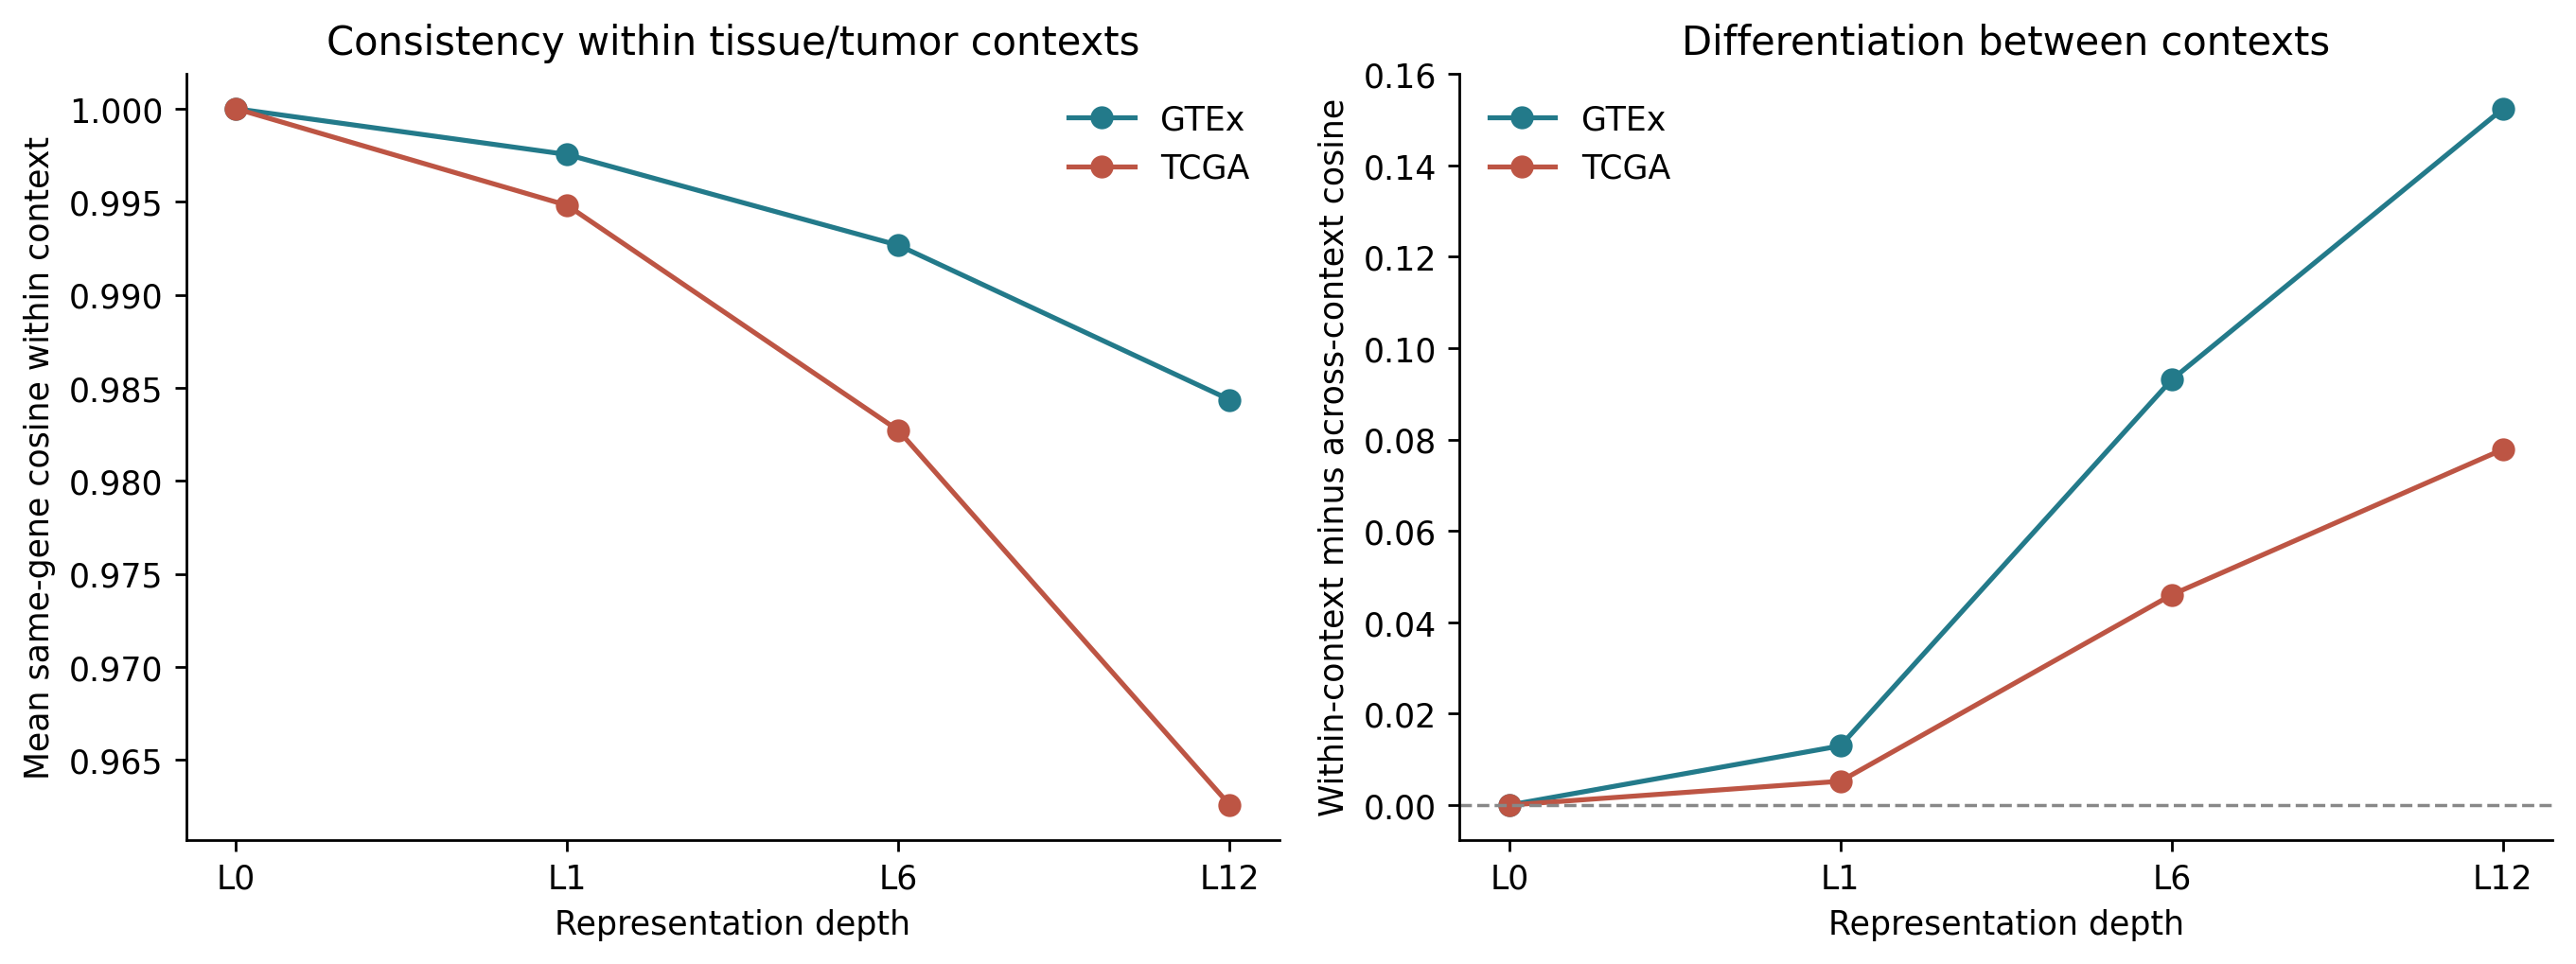

,dataset,layer,within_context_cosine,across_context_cosine,within_minus_across,genes_positive_difference
3,GTEx,L12_final,0.984363,0.831963,0.15240,1.0
7,TCGA,L12_final,0.962585,0.884735,0.07785,1.0


In [6]:
context = pd.read_csv(DATA / 'context_dependence.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for dataset in ['GTEx','TCGA']:
    q = context[context.dataset == dataset].set_index('layer').loc[LAYERS]
    axes[0].plot(range(4), q.within_context_cosine, marker='o', color=COHORT_COLORS[dataset], label=dataset)
    axes[1].plot(range(4), q.within_minus_across, marker='o', color=COHORT_COLORS[dataset], label=dataset)
axes[0].set(ylabel='Mean same-gene cosine within context', title='Consistency within tissue/tumor contexts')
axes[1].set(ylabel='Within-context minus across-context cosine', title='Differentiation between contexts')
axes[1].axhline(0, color='#888', ls='--', lw=1)
for ax in axes:
    ax.set(xticks=range(4), xticklabels=LABELS, xlabel='Representation depth')
    ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, 'within_between_context', context)
display(context.query("layer == 'L12_final'").round(6))


## 4. Does L12 exceed ordinary coexpression?

Pearson and Spearman networks are computed across the same 200 samples per cohort; Bridge uses cohort-mean gene vectors and mean-centered cosine. This **cohort-level** endpoint is distinct from within-sample neighborhoods. Every method excludes genes constant in its cohort: 15,037 eligible GTEx genes and 15,105 eligible TCGA genes.

Functional enrichment is the aggregate shared-term query-neighbor fraction divided by the mean of 100 random-neighbor matrices. Error bars are 95% percentile intervals from 1,000 gene bootstraps with a drawn null replicate. These intervals do not quantify new-cohort reproducibility or form a paired significance test of method differences. L12/best-coexpression ratios are descriptive enrichment comparisons, not information-retention percentages.

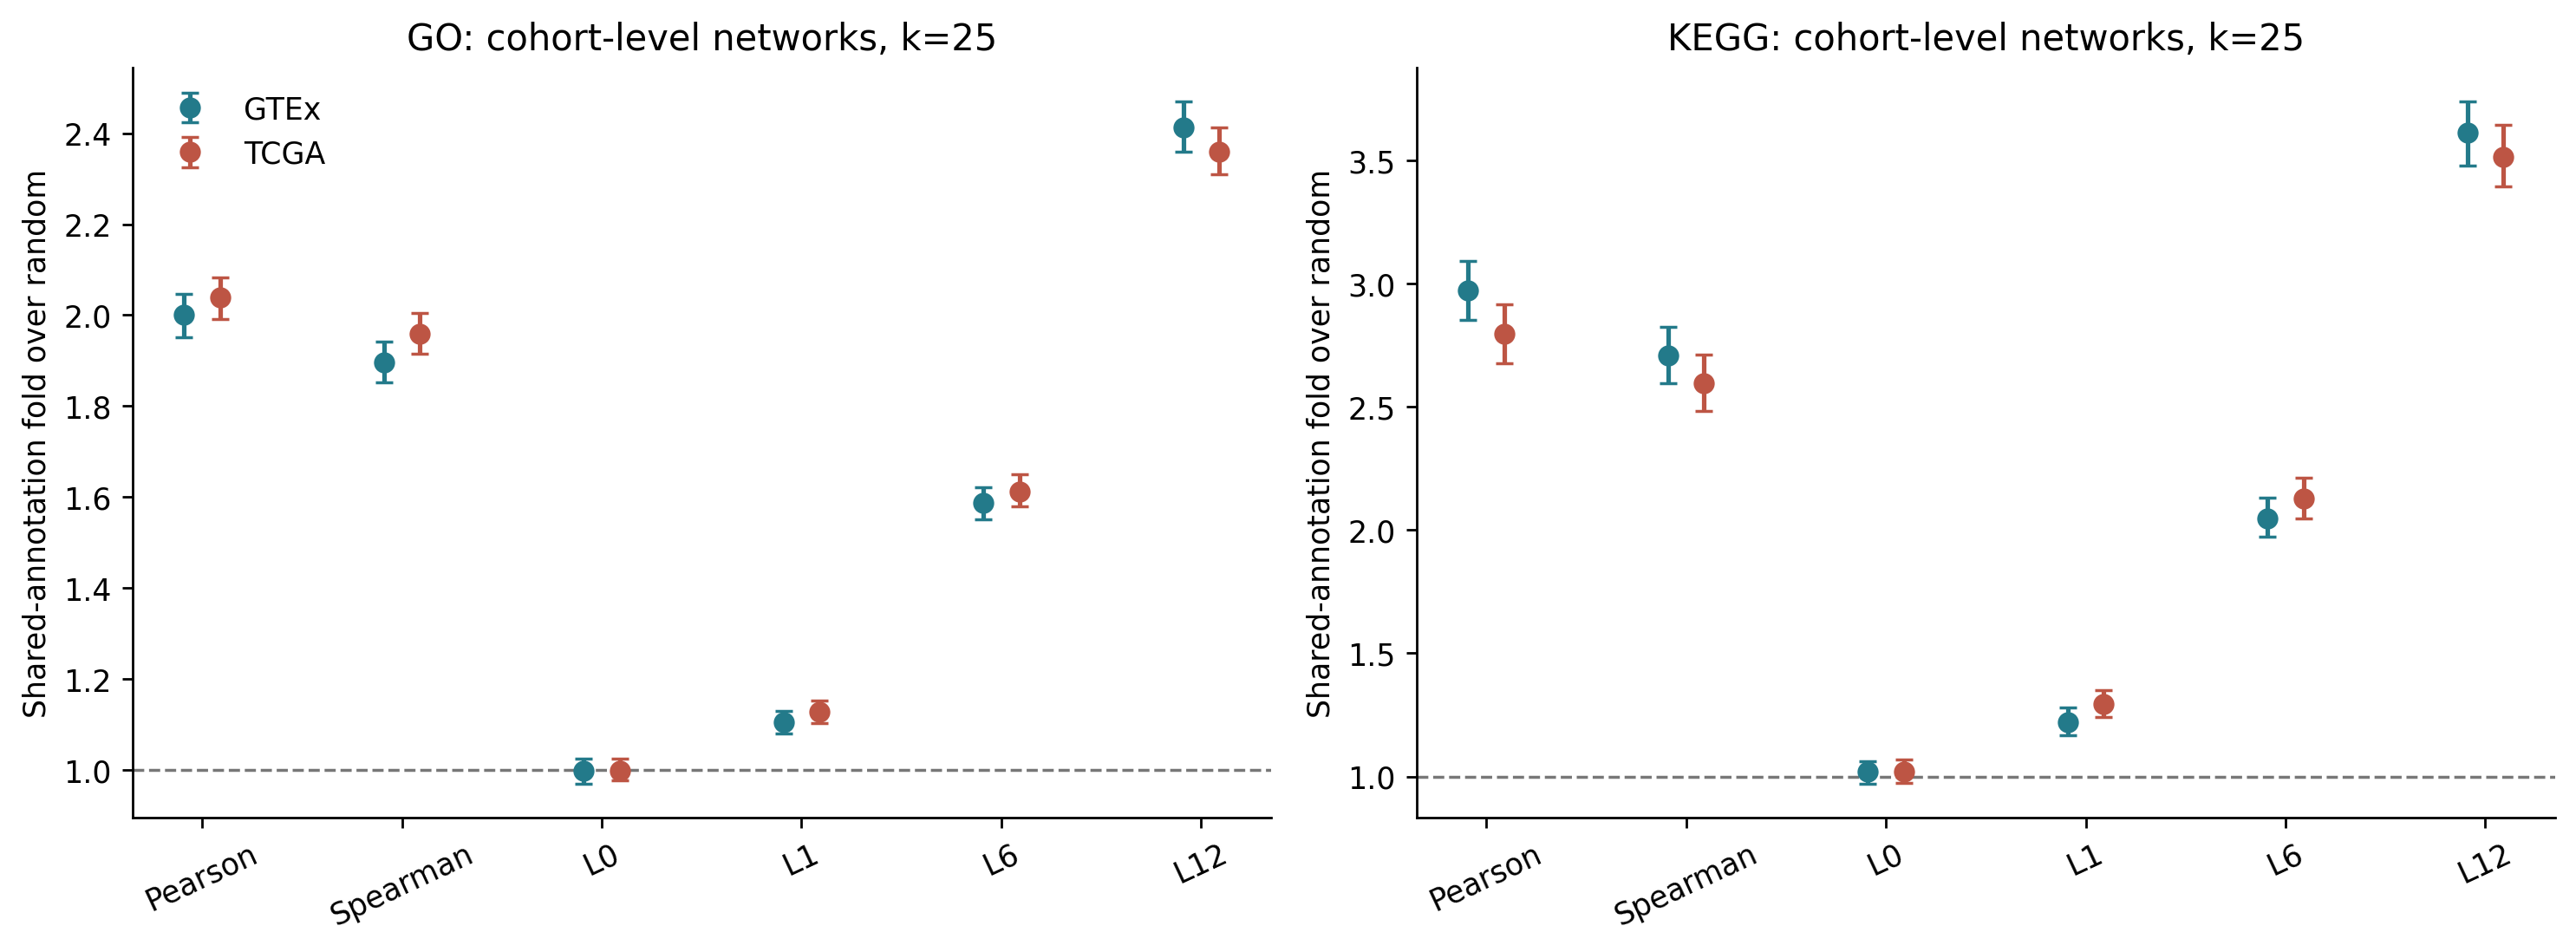

,dataset,library,Bridge L0,Bridge L1,Bridge L12,Bridge L6,Pearson,Spearman,L12_minus_best_coexpression,L12_over_best_coexpression
0,GTEx,GO,0.997778,1.104341,2.412293,1.587750,2.000311,1.895352,0.411982,1.205959
1,GTEx,KEGG,1.018083,1.220618,3.611873,2.048157,2.973288,2.708346,0.638584,1.214774
2,TCGA,GO,0.999253,1.128382,2.359160,1.613033,2.038381,1.958283,0.320779,1.157370
3,TCGA,KEGG,1.018209,1.294499,3.514779,2.127461,2.795839,2.596860,0.718939,1.257146


In [7]:
coex = pd.read_csv(DATA / 'coexpression_comparison.csv')
assert np.allclose(coex.observed_rate / coex.null_mean, coex.fold_over_null, atol=1e-12)
primary_coex = coex[coex.k == 25].copy()
methods = ['Pearson','Spearman','Bridge L0','Bridge L1','Bridge L6','Bridge L12']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, library in zip(axes, ['GO','KEGG']):
    for offset, dataset in [(-.09,'GTEx'),(.09,'TCGA')]:
        q = primary_coex[(primary_coex.dataset == dataset) & (primary_coex.library == library)].set_index('method').loc[methods]
        ax.errorbar(np.arange(6)+offset, q.fold_over_null,
                    yerr=np.vstack([q.fold_over_null-q.ci_low, q.ci_high-q.fold_over_null]),
                    fmt='o', capsize=3, color=COHORT_COLORS[dataset], label=dataset)
    ax.axhline(1, color='#777', ls='--', lw=1)
    ax.set(xticks=range(6), xticklabels=['Pearson','Spearman','L0','L1','L6','L12'],
           ylabel='Shared-annotation fold over random', title=f'{library}: cohort-level networks, k=25')
    ax.tick_params(axis='x', rotation=25)
axes[0].legend(frameon=False)
fig.tight_layout()
save_figure(fig, 'matched_coexpression', primary_coex)
display(pd.read_csv(DATA / 'coexpression_primary_k25.csv').round(6))


## 5. Incremental prediction after expression controls

The binary outcome is whether two annotated genes share a GO term or KEGG pathway. The **base** logistic model contains Pearson, Spearman, pair-average mean `log1p(TPM)`, and absolute mean-expression difference. The **full** model adds L12 cosine. Five-fold anchor-gene GroupKFold uses within-fold standardization and logistic regression (C=10,000); confidence intervals use 500 anchor-gene bootstrap replicates. AP denotes average precision, whose reference depends on class prevalence.

Anchor groups are held out, but partner genes can recur across folds: this is **not fully gene-disjoint evaluation**. Partners were sampled with replacement, producing 722 repeated directed GO rows and 198 repeated directed KEGG rows per cohort. Counts refer to sampled rows, not distinct pairs; the frozen analysis retains their sampling weights. Repeated directed pairs share an anchor group. Representations and correlation networks summarize the complete expression cohort; the target is gene-pair annotation, not future patient outcomes. The following values were recalculated from saved out-of-fold predictions; no models or bootstrap intervals were refitted.

The modest positive increments support added predictive signal beyond the specified covariates. They do not rule out nonlinear expression effects or establish expression-independent biology.

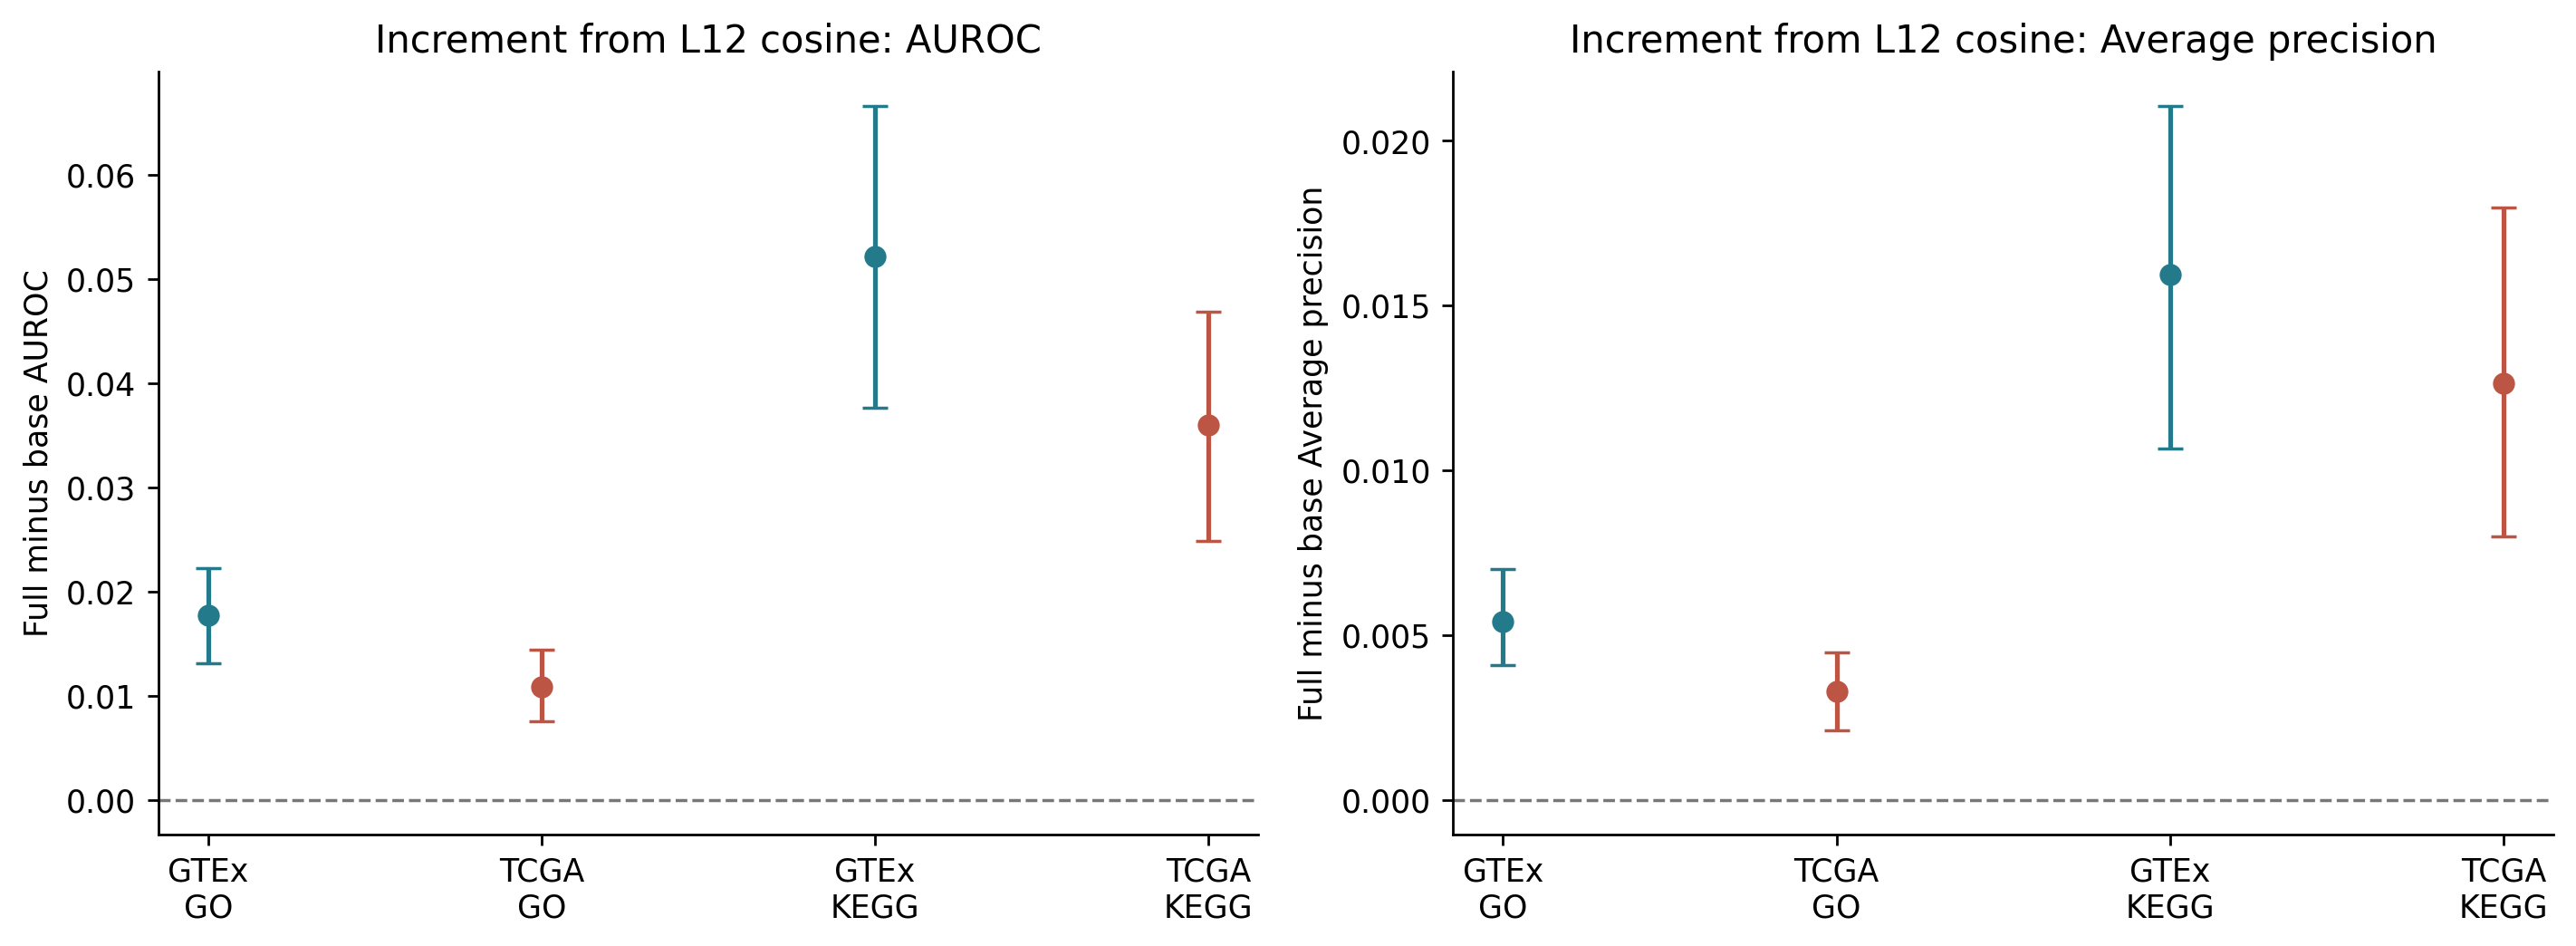

,dataset,library,pairs,positive_pairs,negative_pairs,anchor_genes,base_auroc,full_auroc,delta_auroc,delta_auroc_ci_low,delta_auroc_ci_high,base_auprc,full_auprc,delta_auprc
0,GTEx,GO,211187,14802,196385,2511,0.555027,0.572767,0.017740,0.013142,0.022254,0.086165,0.091576,0.005411
1,GTEx,KEGG,56416,2986,53430,1290,0.532900,0.585089,0.052189,0.037672,0.066615,0.063526,0.079466,0.015940
2,TCGA,GO,211187,14802,196385,2511,0.568405,0.579228,0.010824,0.007573,0.014392,0.090437,0.093743,0.003306
3,TCGA,KEGG,56416,2986,53430,1290,0.556894,0.592913,0.036019,0.024851,0.046874,0.067771,0.080419,0.012648


In [8]:
conditional = pd.read_csv(DATA / 'conditional_results.csv')
recalculated = pd.read_csv(DATA / 'recomputed_prediction_metrics.csv')
check = conditional.merge(recalculated, on=['dataset','library'], validate='one_to_one', suffixes=('_saved','_recomputed'))
for key in ['base_auroc','full_auroc','base_auprc','full_auprc']:
    assert np.allclose(check[key+'_saved'], check[key+'_recomputed'], atol=1e-12, rtol=0)
conditional['negative_pairs'] = conditional.pairs - conditional.positive_pairs
order = [('GTEx','GO'),('TCGA','GO'),('GTEx','KEGG'),('TCGA','KEGG')]
q = conditional.set_index(['dataset','library']).loc[order].reset_index()
fig, axes = plt.subplots(1,2,figsize=(11.5,4.3))
for ax, metric, label in [(axes[0],'auroc','AUROC'),(axes[1],'auprc','Average precision')]:
    for i,row in enumerate(q.itertuples()):
        value = getattr(row,'delta_'+metric)
        low,high = getattr(row,'delta_'+metric+'_ci_low'),getattr(row,'delta_'+metric+'_ci_high')
        ax.errorbar(i,value,yerr=[[value-low],[high-value]],fmt='o',capsize=4,color=COHORT_COLORS[row.dataset])
    ax.axhline(0,color='#777',ls='--',lw=1)
    ax.set(xticks=range(4),xticklabels=[f'{d}\n{lib}' for d,lib in order],
           ylabel=f'Full minus base {label}', title=f'Increment from L12 cosine: {label}')
fig.tight_layout()
save_figure(fig, 'conditional_predictive_gain', conditional)
display(conditional[['dataset','library','pairs','positive_pairs','negative_pairs','anchor_genes',
                     'base_auroc','full_auroc','delta_auroc','delta_auroc_ci_low','delta_auroc_ci_high',
                     'base_auprc','full_auprc','delta_auprc']].round(6))


## 6. Functional modules after linear expression residualization

Cohort-mean gene vectors were clustered with Euclidean K-means (k=10, five seeds 42–46, 10 initializations). A control subtracts each feature's least-squares linear association with cohort mean expression before reclustering. Separate expression-decile modules provide an expression-only reference. GO/KEGG over-representation uses one-sided hypergeometric tests and BH correction within cluster/library.

Bars count significant **cluster–term rows**; terms can recur across clusters and share genes. Persistence after linear residualization shows that simple mean-expression structure is incomplete as an explanation. Neither the counts nor residual/original ratios measure the fraction of biological information retained; linear adjustment does not remove all expression effects.

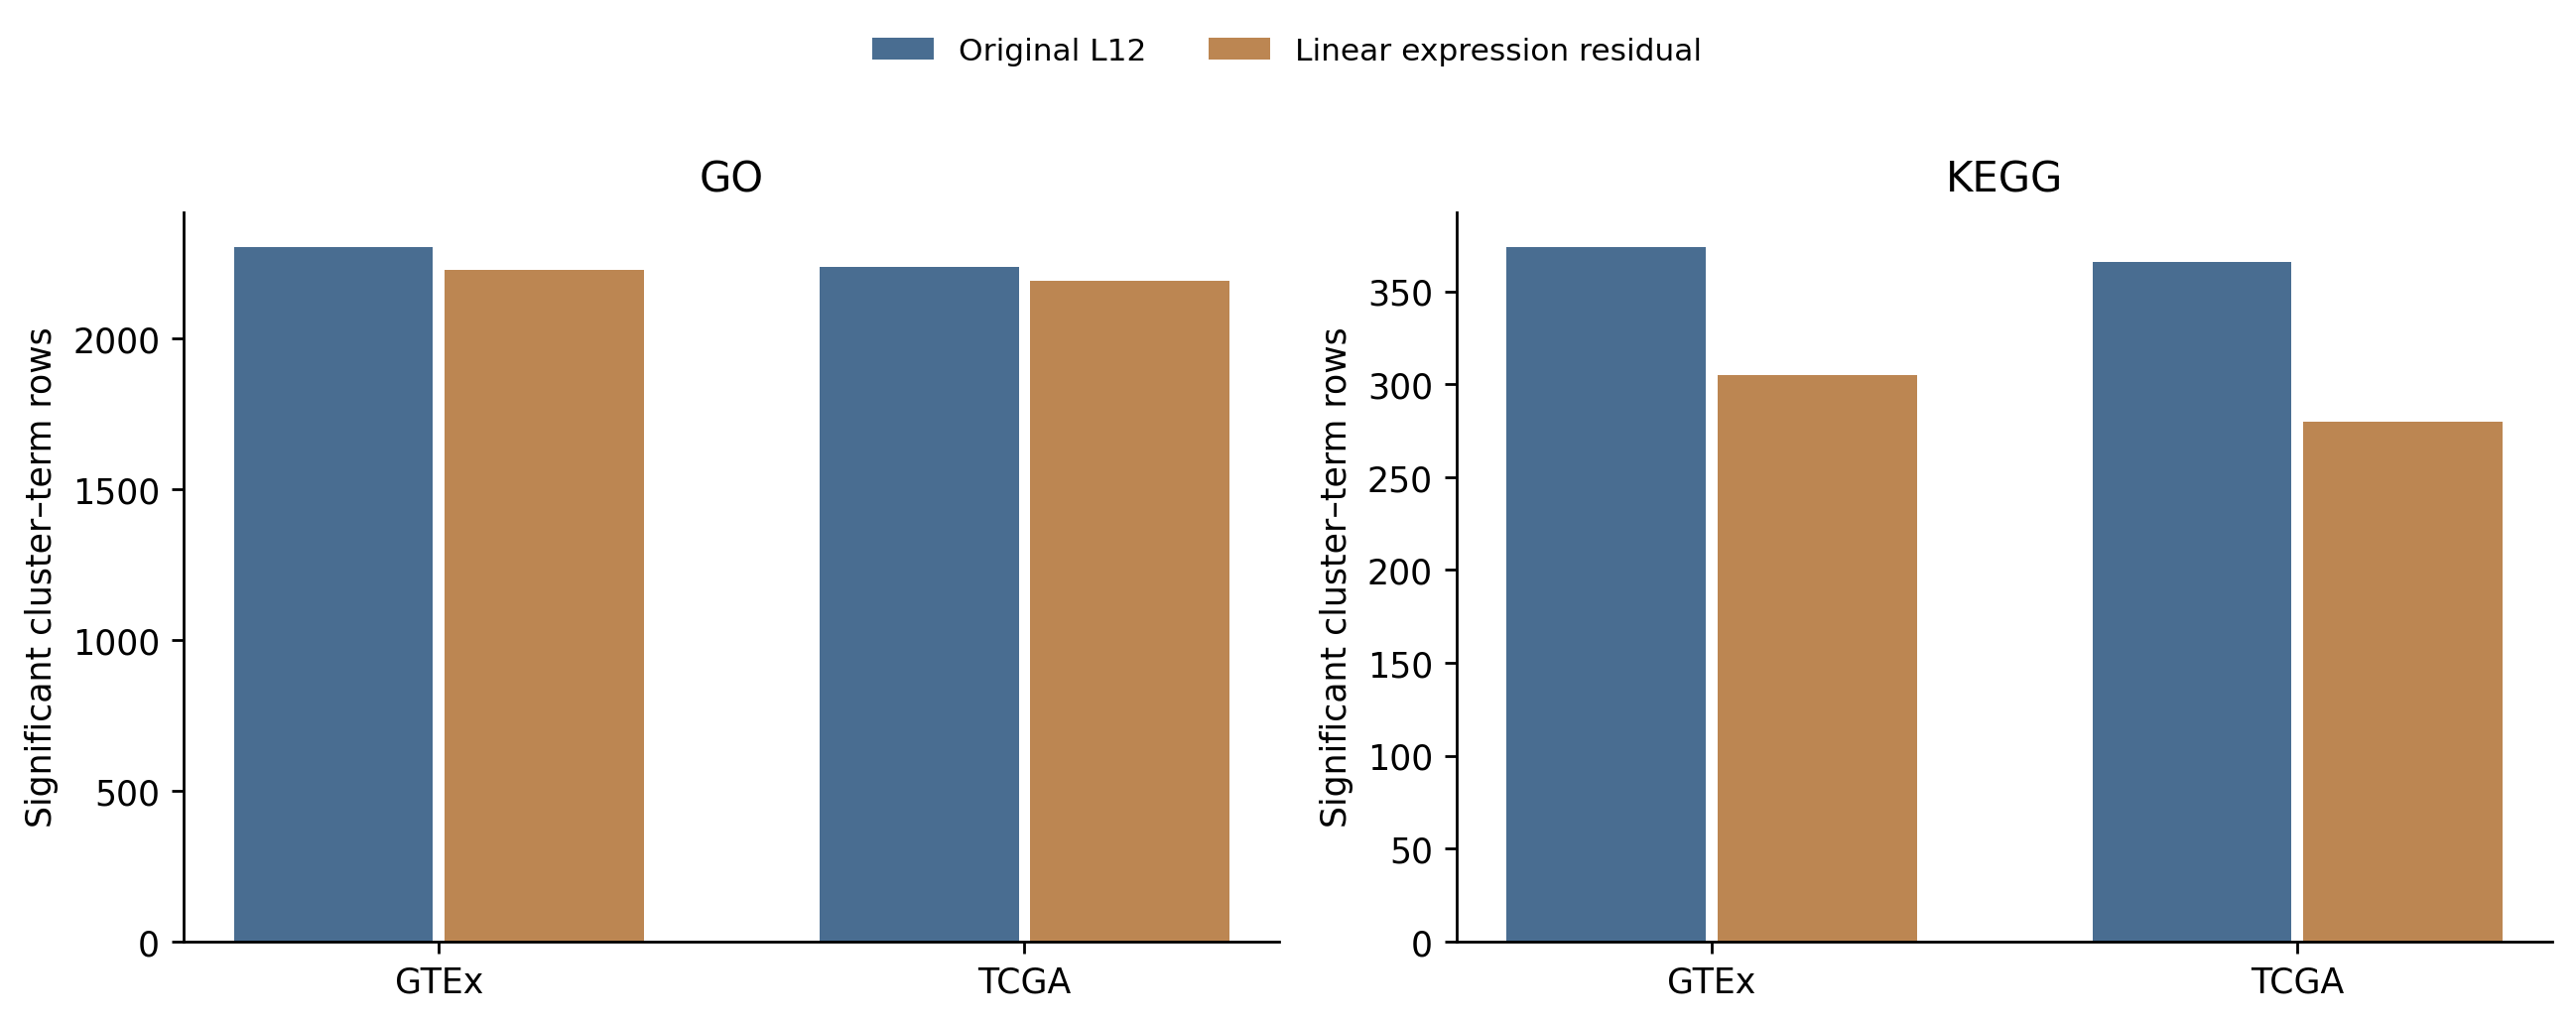

,dataset,control,significant_go_terms,significant_kegg_terms,layer,silhouette,stability_ari
0,GTEx,expression_deciles,382,73,NaN,NaN,NaN
4,GTEx,linear_tpm_residual,2229,305,L12_final,0.019278,0.926587
5,TCGA,expression_deciles,493,98,NaN,NaN,NaN
9,TCGA,linear_tpm_residual,2192,280,L12_final,0.016037,0.858743


In [ ]:
modules = pd.read_csv(DATA / 'module_summary.csv')
controls = pd.read_csv(DATA / 'expression_control_summary.csv')
original = modules.query("layer == 'L12_final'").set_index('dataset')
residual = controls.query("layer == 'L12_final' and control == 'linear_tpm_residual'").set_index('dataset')
fig, axes = plt.subplots(1,2,figsize=(10.5,4.2))
rows=[]
for ax, library in zip(axes,['go','kegg']):
    key='significant_'+library+'_terms'
    for offset, label, frame, color in [(-.18,'Original L12',original,'#496D91'),(.18,'Linear expression residual',residual,'#BC8652')]:
        vals=frame.loc[['GTEx','TCGA'],key]
        ax.bar(np.arange(2)+offset,vals,width=.34,label=label,color=color)
        for dataset,value in vals.items():rows.append({'dataset':dataset,'library':library.upper(),'condition':label,'significant_cluster_term_rows':value})
    ax.set(xticks=range(2),xticklabels=['GTEx','TCGA'],ylabel='Significant cluster–term rows',title=library.upper())
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .99),
           ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, .88])
save_figure(fig,'expression_residual_modules',pd.DataFrame(rows))
display(controls[controls.control.eq('expression_deciles') | controls.layer.eq('L12_final')].round(6))


## Limitations and conclusion

- Related cohorts, annotation libraries, geometries, and k values were explored across several stages; these are not independent confirmatory studies or a preregistered endpoint selection.
- Partner sampling includes repeated directed pair rows; counts are not counts of unique interactions. Annotation overlap is not an independent biological phenotype. Gene/partner reuse, annotation degree, and overlapping terms create dependence; anchor grouping addresses only part of it.
- Early screens have few null repetitions. Later gene/anchor-bootstrap intervals describe their chosen resampling units, not donor/study replication or generalization to unseen studies.
- Pretraining exposure and donor independence have not been established here; GTEx and TCGA are unpaired. Context variation does not establish a cancer mechanism.
- Clustering stability, small silhouettes, and exploratory UMAPs require restrained interpretation; L12 is not uniformly the most visually separated layer.

**Conclusion:** across the sampled depths, functional neighborhoods become stronger than the static identity baseline. Gene states reflect context in two distinct ways—within-context heterogeneity and between-context differentiation. Matched coexpression, linear expression controls, and modest held-out-anchor predictive improvements support functional signal beyond the tested simple baselines, without establishing causal or expression-independent biology.

In [10]:
assert validation['prediction_rows_checked'] == 535206
assert validation['depth_groups_checked'] == 96
assert validation['maximum_metric_difference'] <= validation['absolute_metric_tolerance']
print('Cohort, saved-result, and numerical verification checks passed.')

Cohort, saved-result, and numerical verification checks passed.
